# Training a Neural Network with Backpropagation in NumPy, Line by Line

**Neural Network Lab · CSIT843A Lecture 6** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/NeuralNetwork/code-training.html**

A complete, runnable notebook for chapters 4–6. Roll a ball down a cost curve, write backpropagation by hand, check it numerically, train the 784 → 16 → 16 → 10 network on 60,000 digits to about 95% accuracy, and look at what it learned and where it fails. Only NumPy and Matplotlib. Hover over (or tap) any line of code to see what it does.

**You will learn to:**

1. Take gradient descent steps and see the effect of the learning rate
2. Write backpropagation for a network of any depth
3. Check backpropagation against a numerical slope
4. Train on mini-batches and plot cost and accuracy
5. Inspect learned weights, mistakes and overconfidence

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Setup and data

The same libraries and the same MNIST loader as in the first notebook.

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ececec"

import gzip, os, urllib.request

URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"

def load(name, offset):
    if not os.path.exists(name):
        urllib.request.urlretrieve(URL + name, name)
    with gzip.open(name) as f:
        return np.frombuffer(f.read(), np.uint8, offset=offset)

X_train = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255
y_train = load("train-labels-idx1-ubyte.gz", 8)
X_test = load("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255
y_test = load("t10k-labels-idx1-ubyte.gz", 8)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(60000, 784) (60000,) (10000, 784) (10000,)


**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   Sharper plots in Jupyter.
2. `import numpy as np`  
   Arrays and maths.
3. `import matplotlib.pyplot as plt`  
   Charts.
4. `plt.rcParams["figure.figsize"] = (7, 4)`  
   Default figure size (width, height) in inches.
5. `plt.rcParams["axes.spines.top"] = False` …  
   A cleaner look: hide the top and right borders of every chart.
6. `plt.rcParams["axes.grid"] = True` …  
   Light grid lines make values easier to read.
7. `import gzip, os, urllib.request`  
   Standard-library tools to download and unzip the data files.
8. `URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"`  
   A public copy of the MNIST files on GitHub.
9. `def load(name, offset):`  
   Download one MNIST file (once) and read it as bytes.
10. `if not os.path.exists(name):` …  
   Only download if we do not have the file yet.
11. `with gzip.open(name) as f:`  
   The files are gzip-compressed.
12. `return np.frombuffer(f.read(), np.uint8, offset=offset)`  
   Skip the header (16 bytes for images, 8 for labels) and read the rest as numbers 0–255.
13. `X_train = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255`  
   60,000 training pictures, each a row of 784 pixels, scaled to 0 … 1.
14. `y_train = load("train-labels-idx1-ubyte.gz", 8)`  
   Their labels: the digit 0–9 each picture shows.
15. `X_test = load("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784) / 255` …  
   10,000 test pictures the network never trains on.
16. `print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)`  
   Check the sizes.

## 2. Gradient descent on one weight

Pretend the cost depends on a single weight: $C(w) = 0.05w^4 - 0.5w^2 + 0.3w + 2.2$, with two valleys. Gradient descent repeats $w \leftarrow w - \eta\,\frac{\partial C}{\partial w}$.

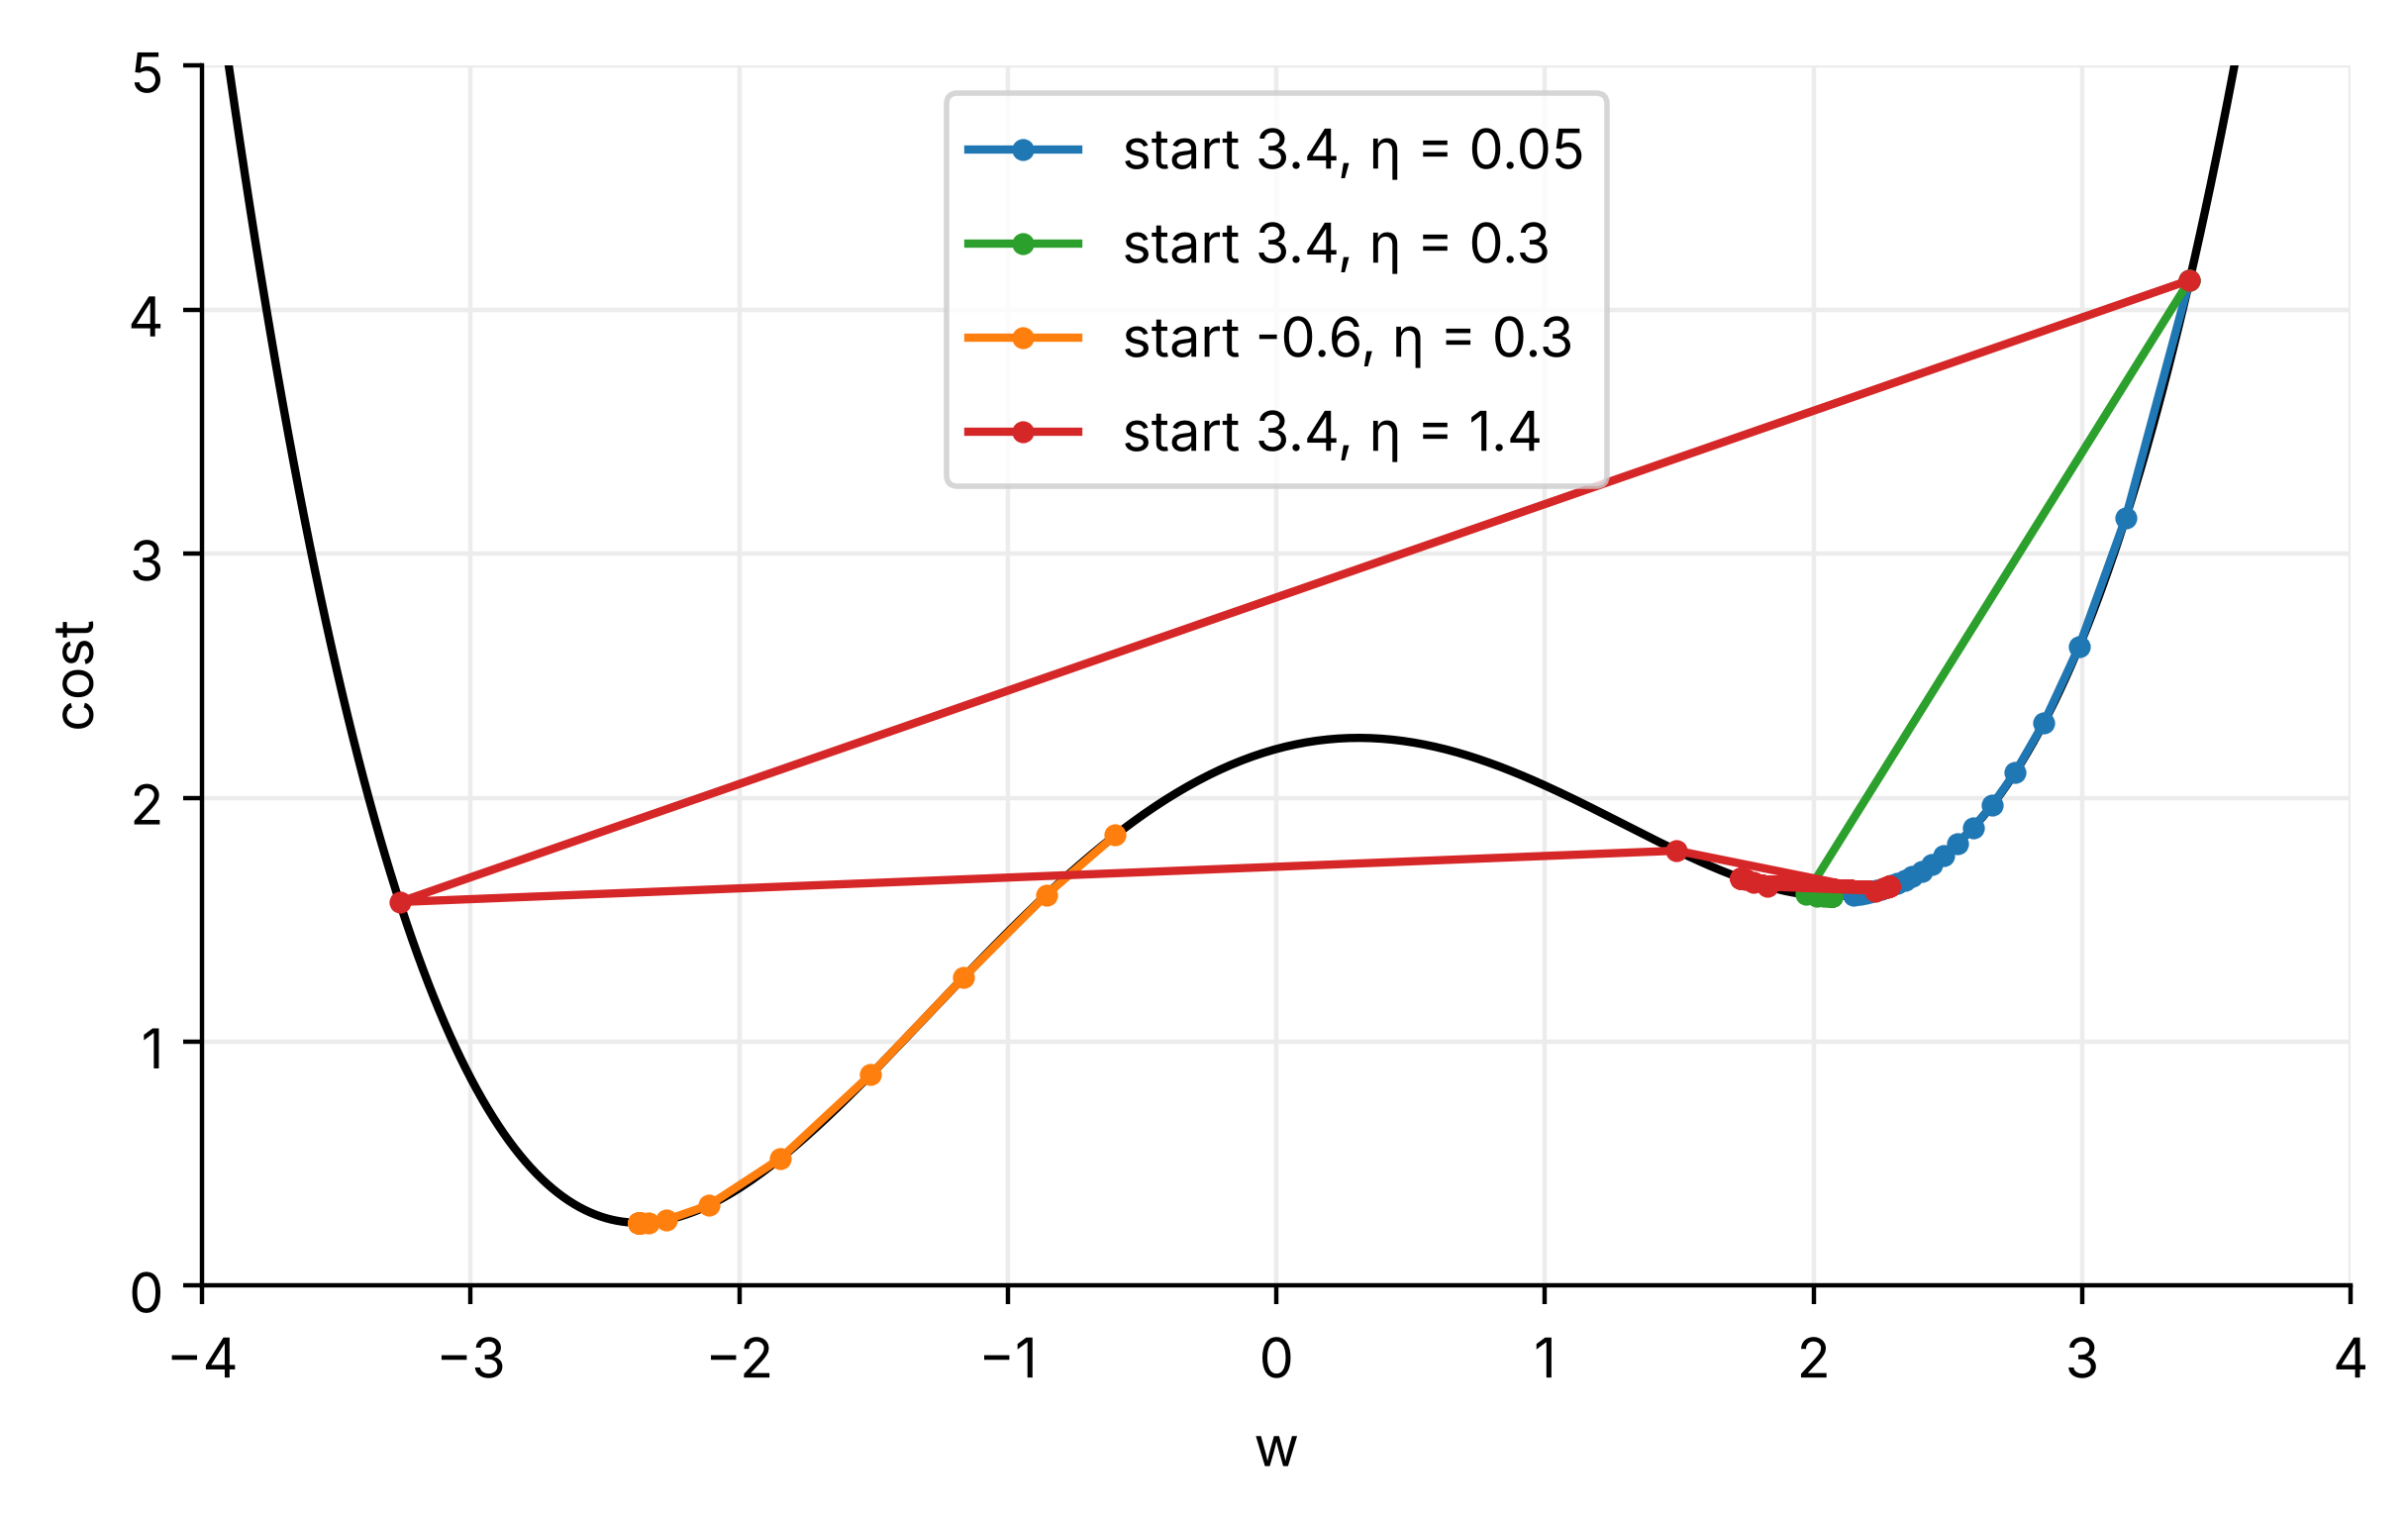

In [2]:
C = lambda w: 0.05 * w**4 - 0.5 * w**2 + 0.3 * w + 2.2
dC = lambda w: 0.2 * w**3 - 1.0 * w + 0.3

def descend(w, eta, steps=25):
    path = [w]
    for _ in range(steps):
        w = w - eta * dC(w)
        path.append(w)
    return np.array(path)

ws = np.linspace(-4, 4, 400)
plt.plot(ws, C(ws), color="black")
for start, eta, col in [(3.4, 0.05, "tab:blue"), (3.4, 0.3, "tab:green"), (-0.6, 0.3, "tab:orange"), (3.4, 1.4, "tab:red")]:
    p = descend(start, eta)
    plt.plot(p, C(p), "o-", ms=3, color=col, label=f"start {start}, η = {eta}")
plt.ylim(0, 5); plt.xlim(-4, 4); plt.legend(); plt.xlabel("w"); plt.ylabel("cost")
plt.show()

**Line by line**

1. `C = lambda w: 0.05 * w**4 - 0.5 * w**2 + 0.3 * w + 2.2`  
   The cost curve.
2. `dC = lambda w: 0.2 * w**3 - 1.0 * w + 0.3`  
   Its slope (the derivative), worked out by hand.
3. `def descend(w, eta, steps=25):` …  
   Run gradient descent and record every position.
4. `w = w - eta * dC(w)` …  
   One step against the slope.
5. `ws = np.linspace(-4, 4, 400)`  
   Points to draw the curve.
6. `plt.plot(ws, C(ws), color="black")`  
   The cost curve.
7. `for start, eta, col in [(3.4, 0.05, "tab:blue"), (3.4, 0.3, "tab:green"), (-0.6, 0.3, "tab:orange"), (3.4, 1.4, "tab:red")]:` …  
   Four runs: different starts and learning rates.
8. `plt.plot(p, C(p), "o-", ms=3, color=col, label=f"start {start}, η = {eta}")`  
   Each dot is one step.
9. `plt.ylim(0, 5); plt.xlim(-4, 4); plt.legend(); plt.xlabel("w"); plt.ylabel("cost")` …  
   Keep the view on the curve.

Small η crawls; a good η settles in a valley; the start decides **which** valley (the right one is a *local minimum*); a too-large η jumps around and can fly away.

## 3. The network and its forward pass

This time the forward pass **keeps every activation**, because backpropagation needs them.

In [3]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
sizes = [784, 16, 16, 10]

def init(seed=0):
    rng = np.random.default_rng(seed)
    W = [rng.normal(0, 1 / np.sqrt(a), (b, a)) for a, b in zip(sizes[:-1], sizes[1:])]
    B = [np.zeros(b) for b in sizes[1:]]
    return W, B

def forward(X, W, B):
    acts = [X]
    for Wl, bl in zip(W, B):
        acts.append(sigmoid(acts[-1] @ Wl.T + bl))
    return acts

**Line by line**

1. `sigmoid = lambda z: 1 / (1 + np.exp(-z))`  
   σ, written as a one-line function.
2. `sizes = [784, 16, 16, 10]`  
   The lecture’s network.
3. `def init(seed=0):` …  
   Fresh random weights and zero biases.
4. `W = [rng.normal(0, 1 / np.sqrt(a), (b, a)) for a, b in zip(sizes[:-1], sizes[1:])]` …  
   Matrices of shape (neurons out, neurons in).
5. `def forward(X, W, B):`  
   X is a batch: one picture per row.
6. `acts = [X]` …  
   acts[0] = the inputs; acts[l] = activations of layer l.
7. `acts.append(sigmoid(acts[-1] @ Wl.T + bl))` …  
   a = σ(W a + b) for the whole batch at once.

## 4. Backpropagation

Start at the output with $\frac{\partial C}{\partial a} = 2(a - y)$. Multiply by the sigmoid’s slope $a(1-a)$ to get δ, the blame on each neuron’s weighted sum. The gradient of a weight is δ × the activation it multiplies. Pass δ back through the weights to the layer before, and repeat. That is the chain rule, layer by layer.

In [4]:
def backward(acts, Y, W):
    n = len(Y)
    delta = 2 * (acts[-1] - Y) * acts[-1] * (1 - acts[-1])
    gW, gB = [None] * len(W), [None] * len(W)
    for l in range(len(W) - 1, -1, -1):
        gW[l] = delta.T @ acts[l] / n
        gB[l] = delta.mean(axis=0)
        if l > 0:
            delta = (delta @ W[l]) * acts[l] * (1 - acts[l])
    return gW, gB

**Line by line**

1. `def backward(acts, Y, W):`  
   Gradients of the average cost over the batch.
2. `n = len(Y)`  
   Number of examples in the batch.
3. `delta = 2 * (acts[-1] - Y) * acts[-1] * (1 - acts[-1])`  
   Output layer: ∂C/∂a × ∂a/∂z.
4. `gW, gB = [None] * len(W), [None] * len(W)`  
   Empty slots, filled from the last layer backwards.
5. `for l in range(len(W) - 1, -1, -1):`  
   l = 2, 1, 0: from the output back to the input.
6. `gW[l] = delta.T @ acts[l] / n`  
   ∂C/∂w = δ × the incoming activation, averaged over the batch.
7. `gB[l] = delta.mean(axis=0)`  
   ∂C/∂b = δ (a bias multiplies 1).
8. `if l > 0:`  
   Not needed before the input layer.
9. `delta = (delta @ W[l]) * acts[l] * (1 - acts[l])` …  
   Pass the blame back through the weights, times this layer’s sigmoid slope.

## 5. Check backpropagation numerically

Nudge one weight by a tiny ε, measure how the cost changes, and compare with what backpropagation says. If the two agree, the code is right.

In [5]:
W, B = init(1)
X, Y = X_train[:20], np.eye(10)[y_train[:20]]
cost = lambda W, B: ((forward(X, W, B)[-1] - Y) ** 2).sum(axis=1).mean()
gW, gB = backward(forward(X, W, B), Y, W)

eps = 1e-5
for (l, j, i) in [(0, 3, 400), (1, 5, 7), (2, 2, 11)]:
    W[l][j, i] += eps; up = cost(W, B)
    W[l][j, i] -= 2 * eps; down = cost(W, B)
    W[l][j, i] += eps
    print(f"layer {l}: numerical {(up - down) / (2 * eps):+.6f}   backprop {gW[l][j, i]:+.6f}")

layer 0: numerical +0.001428   backprop +0.001428
layer 1: numerical -0.003998   backprop -0.003998
layer 2: numerical +0.059474   backprop +0.059474


**Line by line**

1. `W, B = init(1)`  
   A random network.
2. `X, Y = X_train[:20], np.eye(10)[y_train[:20]]`  
   20 examples and their one-hot labels.
3. `cost = lambda W, B: ((forward(X, W, B)[-1] - Y) ** 2).sum(axis=1).mean()`  
   Average cost on these 20 examples.
4. `gW, gB = backward(forward(X, W, B), Y, W)`  
   The gradient from backpropagation.
5. `eps = 1e-5`  
   A tiny nudge.
6. `for (l, j, i) in [(0, 3, 400), (1, 5, 7), (2, 2, 11)]:`  
   Three weights in three different layers.
7. `W[l][j, i] += eps; up = cost(W, B)`  
   Cost with the weight nudged up …
8. `W[l][j, i] -= 2 * eps; down = cost(W, B)`  
   … and nudged down.
9. `W[l][j, i] += eps`  
   Put it back.
10. `print(f"layer {l}: numerical {(up - down) / (2 * eps):+.6f}   backprop {gW[l][j, i]:+.6f}")`  
   The two slopes should match to several decimals.

## 6. Train on mini-batches

Shuffle the 60,000 training digits, cut them into mini-batches of 32, and take one gradient descent step per batch. One pass over all of them is an **epoch**. With learning rate η = 3 this takes about 10 seconds for 30 epochs.

In [6]:
W, B = init(0)
eta, batch, epochs = 3.0, 32, 30
Y_train, Y_test = np.eye(10)[y_train], np.eye(10)[y_test]
rng = np.random.default_rng(0)
history = []

def evaluate():
    out = forward(X_test, W, B)[-1]
    return ((out - Y_test) ** 2).sum(axis=1).mean(), (out.argmax(axis=1) == y_test).mean()

history.append((0, *evaluate()))
for ep in range(1, epochs + 1):
    order = rng.permutation(len(X_train))
    for k in range(0, len(order), batch):
        idx = order[k:k + batch]
        gW, gB = backward(forward(X_train[idx], W, B), Y_train[idx], W)
        for l in range(len(W)):
            W[l] -= eta * gW[l]
            B[l] -= eta * gB[l]
    history.append((ep, *evaluate()))
    if ep % 5 == 0 or ep == 1: print(f"epoch {ep:2d}: test cost {history[-1][1]:.3f}, accuracy {history[-1][2]:.1%}")

epoch  1: test cost 0.117, accuracy 92.5%


epoch  5: test cost 0.088, accuracy 94.4%


epoch 10: test cost 0.085, accuracy 94.5%


epoch 15: test cost 0.085, accuracy 94.8%


epoch 20: test cost 0.087, accuracy 94.8%


epoch 25: test cost 0.088, accuracy 94.5%


epoch 30: test cost 0.084, accuracy 94.7%


**Line by line**

1. `W, B = init(0)`  
   Start again from random weights.
2. `eta, batch, epochs = 3.0, 32, 30`  
   Learning rate, mini-batch size, number of passes.
3. `Y_train, Y_test = np.eye(10)[y_train], np.eye(10)[y_test]`  
   One-hot versions of all labels.
4. `rng = np.random.default_rng(0)`  
   For shuffling.
5. `history = []`  
   (epoch, test cost, test accuracy) after each epoch.
6. `def evaluate():` …  
   Cost and accuracy on the 10,000 test digits.
7. `history.append((0, *evaluate()))`  
   Before training: cost ≈ 3, accuracy ≈ 10%.
8. `for ep in range(1, epochs + 1):`  
   30 epochs.
9. `order = rng.permutation(len(X_train))`  
   A new random order every epoch.
10. `for k in range(0, len(order), batch):`  
   Walk through the data 32 at a time.
11. `idx = order[k:k + batch]`  
   Indices of this mini-batch.
12. `gW, gB = backward(forward(X_train[idx], W, B), Y_train[idx], W)`  
   Forward pass, then backpropagation.
13. `for l in range(len(W)):`  
   Gradient descent step for every layer:
14. `W[l] -= eta * gW[l]` …  
   w ← w − η · gradient.
15. `if ep % 5 == 0 or ep == 1: print(f"epoch {ep:2d}: test cost {history[-1][1]:.3f}, accuracy {history[-1][2]:.1%}")`  
   Report now and then.

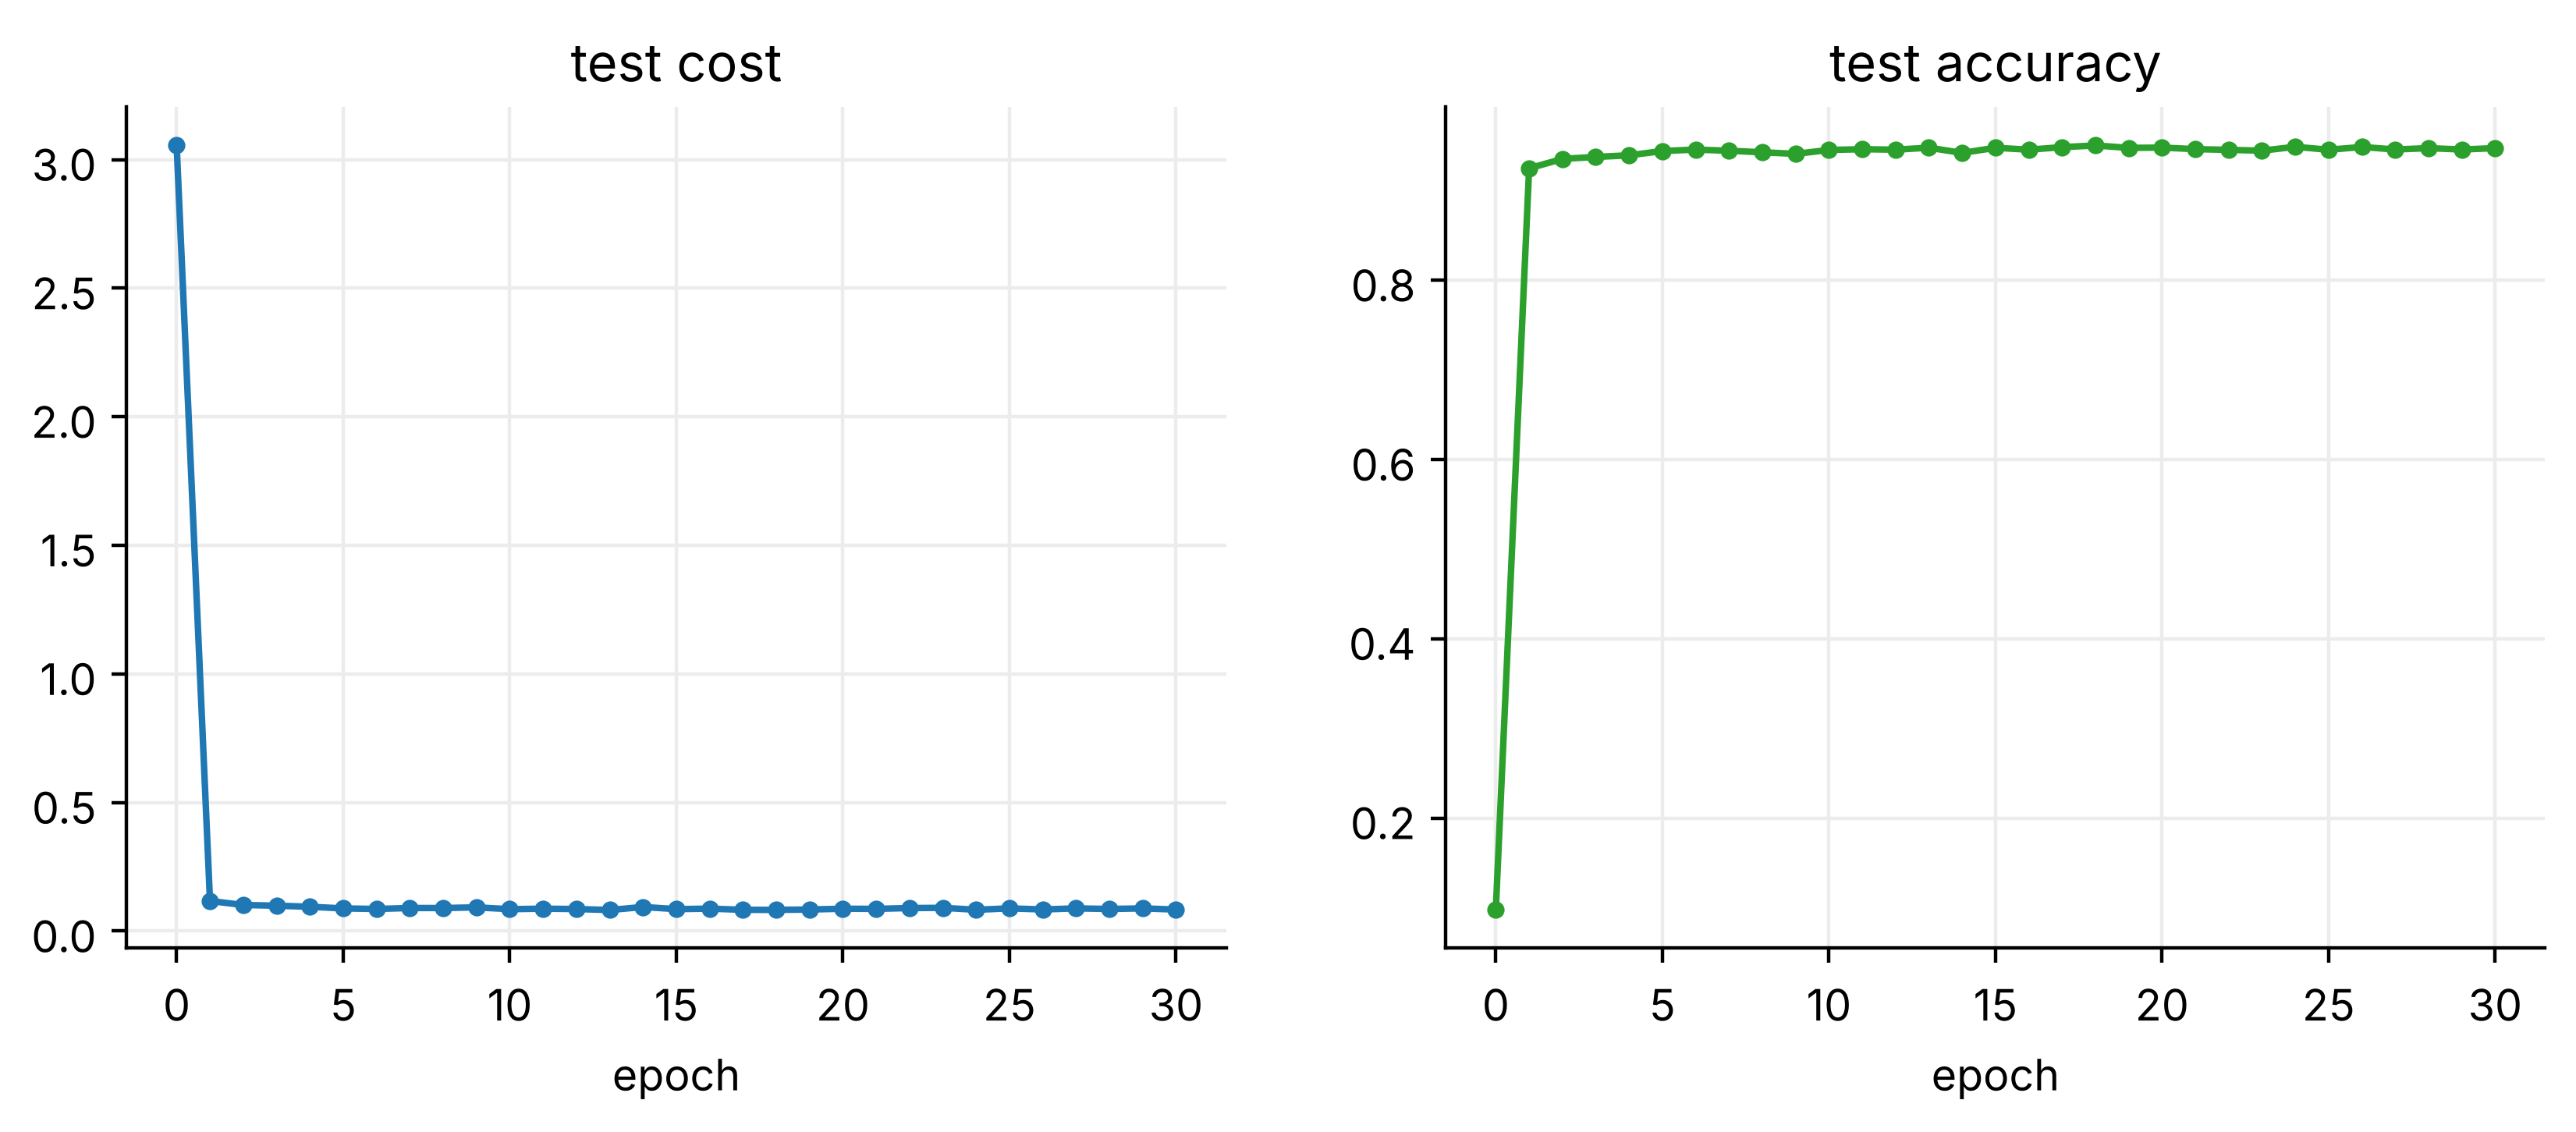

In [7]:
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h[:, 0], h[:, 1], "o-", ms=3); ax[0].set_title("test cost"); ax[0].set_xlabel("epoch")
ax[1].plot(h[:, 0], h[:, 2], "o-", ms=3, color="tab:green"); ax[1].set_title("test accuracy"); ax[1].set_xlabel("epoch")
plt.show()

**Line by line**

1. `h = np.array(history)` …  
   Columns: epoch, cost, accuracy.
2. `ax[0].plot(h[:, 0], h[:, 1], "o-", ms=3); ax[0].set_title("test cost"); ax[0].set_xlabel("epoch")`  
   The cost falls fast, then slowly.
3. `ax[1].plot(h[:, 0], h[:, 2], "o-", ms=3, color="tab:green"); ax[1].set_title("test accuracy"); ax[1].set_xlabel("epoch")` …  
   From about 10% to about 95%.

## 7. What did it learn?

Each first-layer neuron has 784 weights: draw them as a 28 × 28 picture (green positive, red negative).

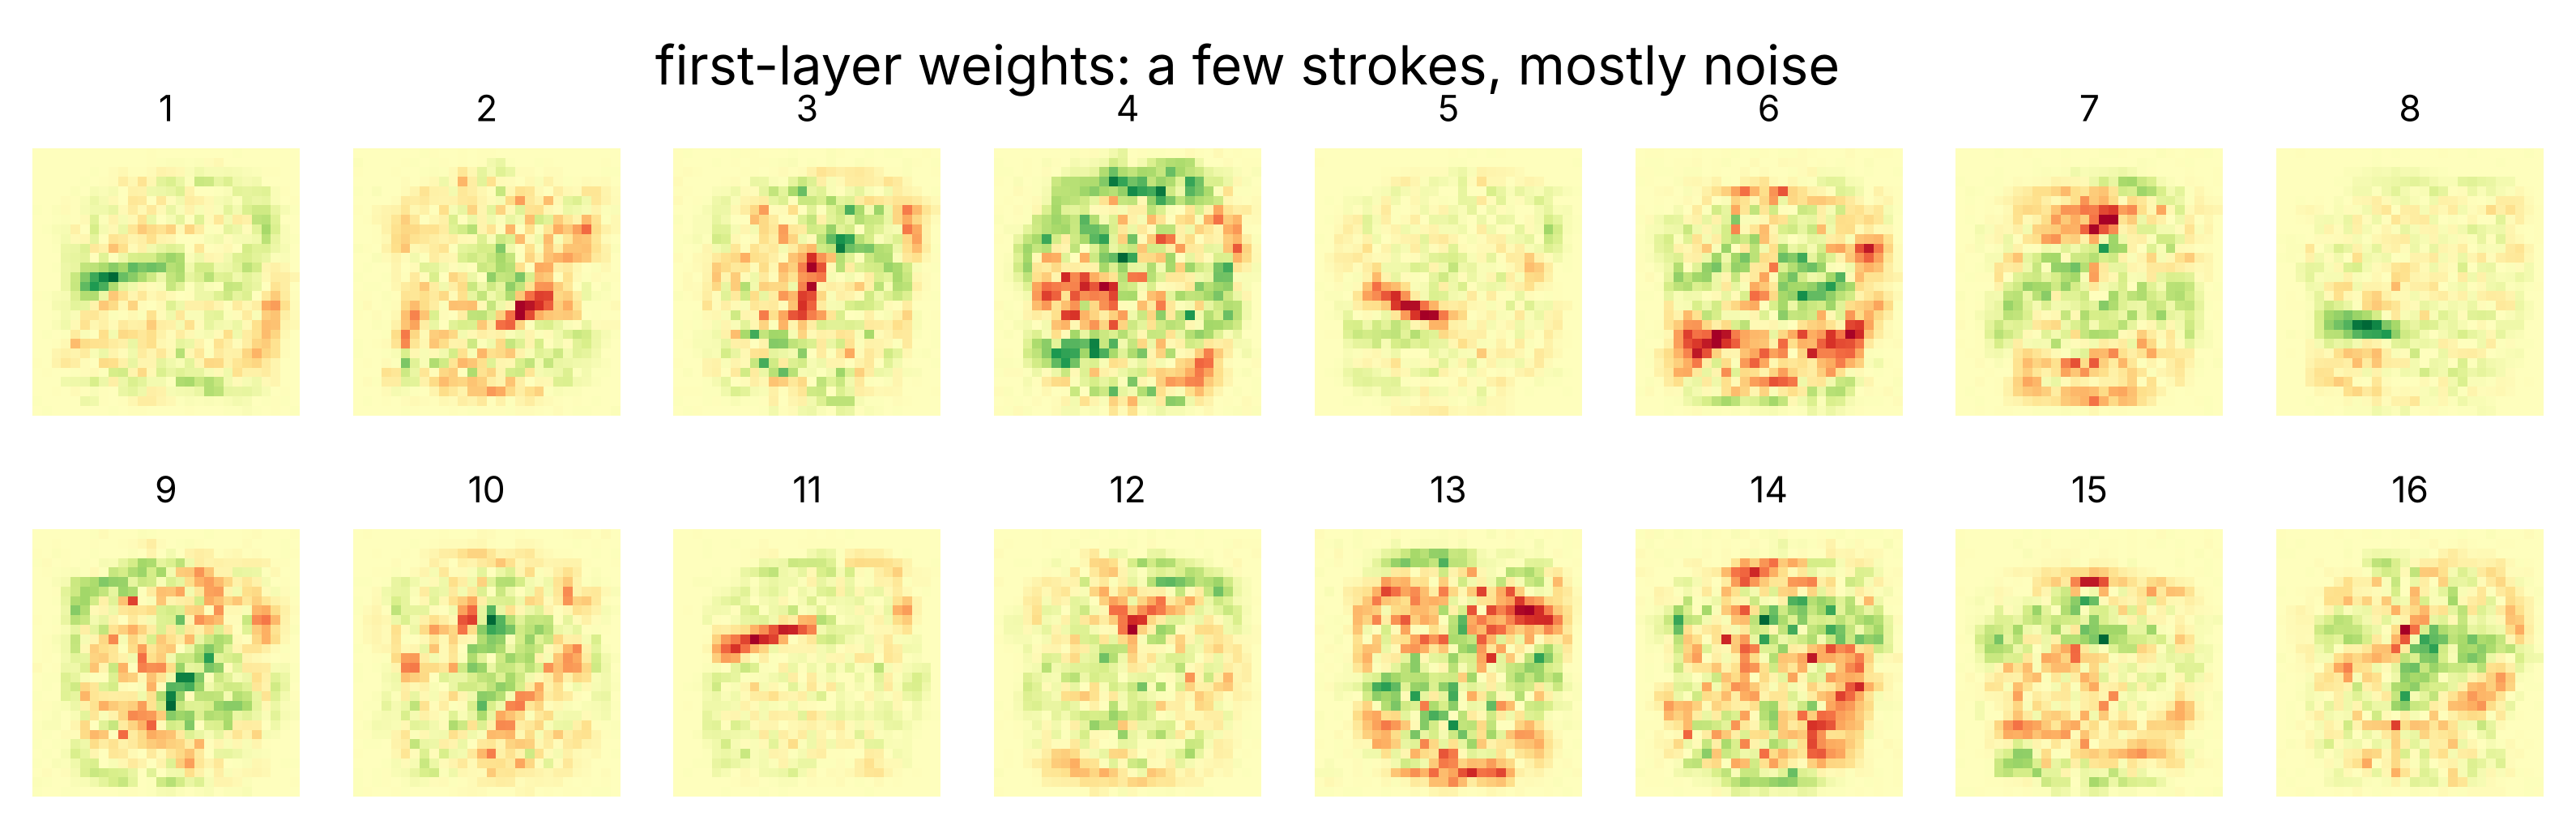

In [8]:
fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for k, ax in enumerate(axes.ravel()):
    m = np.abs(W[0][k]).max()
    ax.imshow(W[0][k].reshape(28, 28), cmap="RdYlGn", vmin=-m, vmax=m)
    ax.set_title(k + 1, fontsize=8); ax.axis("off")
plt.suptitle("first-layer weights: a few strokes, mostly noise")
plt.show()

**Line by line**

1. `fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))` …  
   16 neurons in hidden layer 1.
2. `m = np.abs(W[0][k]).max()`  
   Use the same colour scale for + and −.
3. `ax.imshow(W[0][k].reshape(28, 28), cmap="RdYlGn", vmin=-m, vmax=m)` …  
   Red = negative weight, green = positive.

## 8. Its mistakes

Show some test digits it gets wrong, and the confusion matrix: rows are the true digit, columns what the network said.

527 mistakes out of 10000


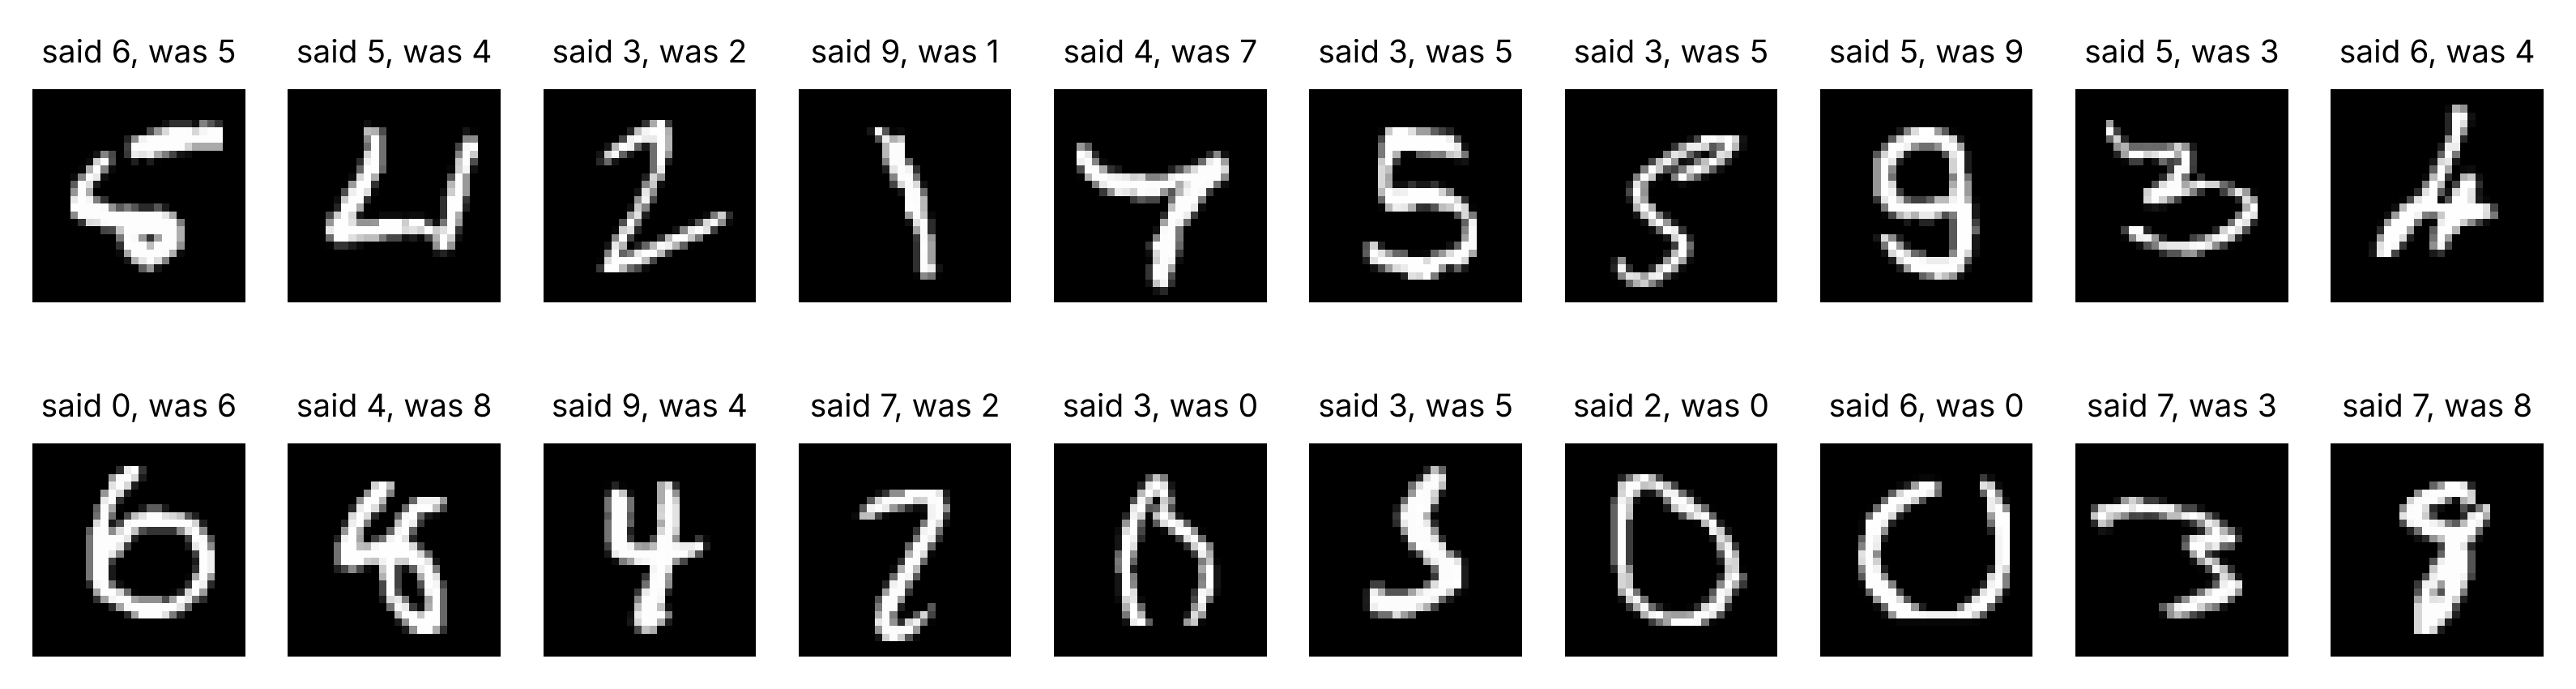

[[ 955    0    2    2    0    5    9    7    0    0]
 [   1 1115    0    4    1    0    3    2    8    1]
 [  16    3  970   14    6    1    4    5   12    1]
 [   0    0   13  967    0   11    0    6   12    1]
 [   1    1    2    0  943    2    9    3    4   17]
 [  10    1    0   42   10  793   14    3   14    5]
 [   7    1    2    0    7    2  923    1   15    0]
 [   1   13   20    5    4    0    1  961    3   20]
 [   6    5    5   17    7    4   10    7  912    1]
 [   3    1    1   15   23    9    0   17    6  934]]


In [9]:
pred = forward(X_test, W, B)[-1].argmax(axis=1)
wrong = np.where(pred != y_test)[0]
print(f"{len(wrong)} mistakes out of {len(y_test)}")

fig, axes = plt.subplots(2, 10, figsize=(10, 2.6))
for i, ax in zip(wrong[:20], axes.ravel()):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray"); ax.axis("off")
    ax.set_title(f"said {pred[i]}, was {y_test[i]}", fontsize=7)
plt.show()

conf = np.zeros((10, 10), int)
np.add.at(conf, (y_test, pred), 1)
print(conf)

**Line by line**

1. `pred = forward(X_test, W, B)[-1].argmax(axis=1)`  
   The network’s answer for every test digit.
2. `wrong = np.where(pred != y_test)[0]` …  
   Indices of the mistakes.
3. `fig, axes = plt.subplots(2, 10, figsize=(10, 2.6))` …  
   20 of them.
4. `conf = np.zeros((10, 10), int)`  
   Confusion matrix.
5. `np.add.at(conf, (y_test, pred), 1)`  
   Add 1 at (true, said) for every test digit.
6. `print(conf)`  
   Large numbers off the diagonal are common confusions (4 ↔ 9, 3 ↔ 5, …).

## 9. It does not know what it does not know

Feed it random noise. It still answers, often confidently, because it was never taught to say “not a digit”.

In [10]:
noise = np.random.default_rng(1).random((5, 784))
out = forward(noise, W, B)[-1]
for o in out:
    print("answer", o.argmax(), " confidence", o.max().round(2))

answer 6  confidence 0.57
answer 8  confidence 0.7
answer 0  confidence 0.58
answer 8  confidence 0.1
answer 8  confidence 0.06


**Line by line**

1. `noise = np.random.default_rng(1).random((5, 784))` …  
   Five pictures of pure random pixels.
2. `print("answer", o.argmax(), " confidence", o.max().round(2))`  
   An answer every time: confidence outside the training data means nothing.

## 10. What you built

Forward pass, cost, backpropagation, gradient descent: about 30 lines of NumPy, the same loop as `loss.backward()` and `optimizer.step()` in PyTorch. **Next notebook:** convolution filters and the three training problems of chapter 10.